<a href="https://colab.research.google.com/github/And850/VeritasHackathonProject1/blob/main/VeritasHackathon.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Setup and Imports
This cell imports the necessary libraries for data manipulation, datasets loading, and audio display.


In [1]:
import IPython.display as ipd
import pandas as pd
import glob
import os
import numpy as np
from datasets import load_dataset

## Load (and check) `saeedzou/sep28k-fluencybank-stutter-dataset`

### Step 1: Stream and Preview Dataset
We load the dataset in streaming mode to inspect its structure and retrieve the column headers without downloading the entire dataset.


In [2]:
# Load dataset in streaming mode to inspect metadata and columns safely
ds = load_dataset('saeedzou/sep28k-fluencybank-stutter-dataset', streaming=True)

# Get the first sample to inspect columns and keys
sample = next(iter(ds['train']))
print("Columns/Keys available in a sample:", list(sample.keys()))

README.md:   0%|          | 0.00/956 [00:00<?, ?B/s]

Columns/Keys available in a sample: ['audio', 'Show', 'EpId', 'ClipId', 'Start', 'Stop', 'Unsure', 'PoorAudioQuality', 'Prolongation', 'Block', 'SoundRep', 'WordRep', 'DifficultToUnderstand', 'Interjection', 'NoStutteredWords', 'NaturalPause', 'Music', 'NoSpeech']


### Step 2: Interactive Play Check
This cell pulls the first 5 samples from the streaming dataset for optional listening and label verification.


In [3]:
# Fetch 5 samples
samples = list(ds['train'].take(5))

for i, s in enumerate(samples):
    print(f"--- Clip {i+1} ---")
    print(f"Show: {s.get('Show')}")
    print(f"EpId: {s.get('EpId')}")
    print(f"ClipId: {s.get('ClipId')}")

    # Display label-related columns if they exist
    labels = {k: v for k, v in s.items() if k not in ['audio', 'Show', 'EpId', 'ClipId']}
    print("Labels:", labels)

    # Play the audio
    audio_data = s['audio']['array']
    sr = s['audio']['sampling_rate']
    ipd.display(ipd.Audio(audio_data, rate=sr))
    print("\n")

--- Clip 1 ---
Show: HeStutters
EpId: 0
ClipId: 17
Labels: {'Start': 6970880, 'Stop': 7018880, 'Unsure': 0, 'PoorAudioQuality': 0, 'Prolongation': 0, 'Block': 0, 'SoundRep': 0, 'WordRep': 0, 'DifficultToUnderstand': 0, 'Interjection': 0, 'NoStutteredWords': 3, 'NaturalPause': 1, 'Music': 0, 'NoSpeech': 0}




--- Clip 2 ---
Show: HeStutters
EpId: 0
ClipId: 18
Labels: {'Start': 8215200, 'Stop': 8263200, 'Unsure': 0, 'PoorAudioQuality': 0, 'Prolongation': 0, 'Block': 1, 'SoundRep': 0, 'WordRep': 0, 'DifficultToUnderstand': 0, 'Interjection': 0, 'NoStutteredWords': 2, 'NaturalPause': 1, 'Music': 0, 'NoSpeech': 0}




--- Clip 3 ---
Show: HeStutters
EpId: 0
ClipId: 19
Labels: {'Start': 9985280, 'Stop': 10033280, 'Unsure': 0, 'PoorAudioQuality': 0, 'Prolongation': 1, 'Block': 0, 'SoundRep': 0, 'WordRep': 0, 'DifficultToUnderstand': 0, 'Interjection': 0, 'NoStutteredWords': 2, 'NaturalPause': 0, 'Music': 0, 'NoSpeech': 0}




--- Clip 4 ---
Show: HeStutters
EpId: 0
ClipId: 20
Labels: {'Start': 11197600, 'Stop': 11245600, 'Unsure': 0, 'PoorAudioQuality': 0, 'Prolongation': 0, 'Block': 0, 'SoundRep': 0, 'WordRep': 0, 'DifficultToUnderstand': 0, 'Interjection': 0, 'NoStutteredWords': 3, 'NaturalPause': 0, 'Music': 0, 'NoSpeech': 0}




--- Clip 5 ---
Show: HeStutters
EpId: 0
ClipId: 26
Labels: {'Start': 3562240, 'Stop': 3610240, 'Unsure': 0, 'PoorAudioQuality': 0, 'Prolongation': 0, 'Block': 0, 'SoundRep': 0, 'WordRep': 0, 'DifficultToUnderstand': 0, 'Interjection': 0, 'NoStutteredWords': 3, 'NaturalPause': 0, 'Music': 0, 'NoSpeech': 0}



### Step 3: Clone Extended Metadata Repository
We clone the repository containing extended metadata such as speaker identities, audio quality metrics, and predefined dataset splits.


In [4]:
if not os.path.exists('sep28k_e'):
    !git clone -q https://github.com/th-nuernberg/ml-stuttering-events-dataset-extended sep28k_e
else:
    print("sep28k_e already exists. Skipping clone.")


### Step 4: Parse Extended Metadata Files
We parse the metadata files from the extended repository and normalize standard key columns.

In [5]:
ext = pd.read_csv("sep28k_e/SEP-28k-Extended_clips.csv")
eps = pd.read_csv("sep28k_e/SEP-28k-Extended_episodes.csv")

for d in (ext, eps):
    d["Show"] = d["Show"].astype(str).str.strip()
    d["EpId"] = d["EpId"].astype(int)
ext["ClipId"] = ext["ClipId"].astype(int)


### Step 5: Full Dataset Loading
We load the complete Hugging Face dataset locally to extract metadata and prepare for alignment.


In [6]:
ds_full = load_dataset('saeedzou/sep28k-fluencybank-stutter-dataset')
print(ds_full)

data/train-00000-of-00007.parquet: reconstructing file:   0%|          |  0.00B /  413MB            

data/train-00000-of-00007.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00007.parquet: reconstructing file:   0%|          |  0.00B /  396MB            

data/train-00001-of-00007.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00007.parquet: reconstructing file:   0%|          |  0.00B /  407MB            

data/train-00002-of-00007.parquet: downloading bytes:           |  0.00B            

... (6 outputs left out)

data/train-00006-of-00007.parquet: reconstructing file:   0%|          |  0.00B /  429MB            

data/train-00006-of-00007.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/31908 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['audio', 'Show', 'EpId', 'ClipId', 'Start', 'Stop', 'Unsure', 'PoorAudioQuality', 'Prolongation', 'Block', 'SoundRep', 'WordRep', 'DifficultToUnderstand', 'Interjection', 'NoStutteredWords', 'NaturalPause', 'Music', 'NoSpeech'],
        num_rows: 31908
    })
})



### Step 6: Extract and Normalize Mirror Metadata
We extract tabular metadata (excluding heavy audio arrays) from the Hugging Face dataset and enforce standard types.


In [7]:
# Extract meta
meta = ds_full['train'].remove_columns('audio').to_pandas()

# Normalize keys
for d in (meta, ext, eps):
    d['Show'] = d['Show'].astype(str).str.strip()
    d['EpId'] = d['EpId'].astype(int)

ext['ClipId'] = ext['ClipId'].astype(int)
meta['ClipId'] = meta['ClipId'].astype(int)

print("Meta keys normalized. Columns:", list(meta.columns))

Meta keys normalized. Columns: ['Show', 'EpId', 'ClipId', 'Start', 'Stop', 'Unsure', 'PoorAudioQuality', 'Prolongation', 'Block', 'SoundRep', 'WordRep', 'DifficultToUnderstand', 'Interjection', 'NoStutteredWords', 'NaturalPause', 'Music', 'NoSpeech']



### Step 7: Build Master Table
We perform key-based merges to align the extended labels, episode attributes (gender), and verify alignment against the HF dataset.


In [8]:
# Merge ext with eps
df_master = ext.merge(eps[['Show', 'EpId', 'host_gender', 'guest_gender']], on=['Show', 'EpId'], how='left')

# Check audio existence in mirror metadata
meta_keys = set(zip(meta['Show'], meta['EpId'], meta['ClipId']))
df_master['has_audio'] = df_master.apply(lambda row: (row['Show'], row['EpId'], row['ClipId']) in meta_keys, axis=1)

# Calculate gender mapping
df_master['gender'] = df_master.apply(
    lambda r: r['host_gender'] if r['is_probably_host'] == True else r['guest_gender'], axis=1
)

print(f"Master dataframe built with {len(df_master)} clips.")

Master dataframe built with 28177 clips.



### Step 8: Label Definition
We define the binary label `stutter`. `stutter` is set to 1 if any of Prolongation, Block, SoundRep, or WordRep receives 2 or more votes. Interjections are left out of this metric to focus on core stuttering behaviors.


In [9]:
# Compute binary stutter indicator
stutter_cols = ['Prolongation', 'Block', 'SoundRep', 'WordRep']
df_master['stutter'] = df_master[stutter_cols].apply(lambda row: 1 if (row >= 2).any() else 0, axis=1)

print("Binary stutter rate defined.")

Binary stutter rate defined.



### Step 9: Dataset Filtering
We systematically filter out samples with missing speaker annotations, missing audio alignments, or excessive audio corruption/noise.


In [10]:
initial_rows = len(df_master)

# Missing speaker filter
no_speaker = df_master['speaker'].isna()
print(f"Rows removed due to missing speaker: {no_speaker.sum()}")
df_filtered = df_master[~no_speaker].copy()

# No audio filter
no_audio = df_filtered['has_audio'] == False
print(f"Rows removed due to missing audio in mirror: {no_audio.sum()}")
df_filtered = df_filtered[~no_audio].copy()

# Quality filters
corrupted = (
    (df_filtered['PoorAudioQuality'] >= 2) |
    (df_filtered['Music'] >= 2) |
    (df_filtered['NoSpeech'] >= 2) |
    (df_filtered['DifficultToUnderstand'] >= 2)
)
print(f"Rows removed due to poor quality/music/no speech/difficult to understand: {corrupted.sum()}")
df_filtered = df_filtered[~corrupted].copy()

print(f"Total rows remaining: {len(df_filtered)} (out of {initial_rows})")

Rows removed due to missing speaker: 160
Rows removed due to missing audio in mirror: 255
Rows removed due to poor quality/music/no speech/difficult to understand: 1897
Total rows remaining: 25865 (out of 28177)


Since the original `SEP28k-E` train split contains only 4 unique speakers, we construct a new partition of the data to facilitate better calibration and model validation. We preserve the original test set, retain the original train set, and dynamically partition the original development set's speakers into two halves: one added to the train set, and the other designated as a calibration fold (`calib`).

In [11]:
dev_subset = df_filtered[df_filtered['SEP28k-E'] == 'dev']
unique_dev_speakers = sorted(dev_subset['speaker'].dropna().unique())

rng = np.random.default_rng(42)
shuffled_dev_speakers = unique_dev_speakers.copy()
rng.shuffle(shuffled_dev_speakers)

split_idx = len(shuffled_dev_speakers) // 2
train_extra_speakers = set(shuffled_dev_speakers[:split_idx])
calib_speakers = set(shuffled_dev_speakers[split_idx:])

def assign_split(row):
    orig = row['SEP28k-E']
    if orig == 'test':
        return 'test'
    elif orig == 'train':
        return 'train'
    elif orig == 'dev':
        spk = row['speaker']
        if spk in train_extra_speakers:
            return 'train'
        elif spk in calib_speakers:
            return 'calib'
    return 'unassigned'

df_filtered['split'] = df_filtered.apply(assign_split, axis=1)


### Step 10: Sanity Checks
We run verification diagnostics on each predefined split of the dataset, ensuring no speaker overlap across splits.


In [12]:
splits = ['train', 'calib', 'test']
print(f"{'-'*95}\n{'Split':<10} | {'Clips':<10} | {'Speakers':<10} | {'Spk >= 10Clips':<14} | {'Max Spk Clips':<14} | {'Stutter Rate':<12} | {'Gender counts'}\n{'-'*95}")

speakers_by_split = {}

for s in splits:
    sub = df_filtered[df_filtered['split'] == s]
    n_clips = len(sub)
    n_spk = sub['speaker'].nunique()

    # Count speakers with at least 10 clips in this split
    spk_counts = sub['speaker'].value_counts()
    spk_ge10 = (spk_counts >= 10).sum()

    max_spk = spk_counts.max() if n_clips > 0 else 0
    stutter_rate = sub['stutter'].mean() if n_clips > 0 else 0
    genders = sub['gender'].value_counts().to_dict()

    speakers_by_split[s] = set(sub['speaker'].dropna().unique())

    print(f"{s:<10} | {n_clips:<10} | {n_spk:<10} | {spk_ge10:<14} | {max_spk:<14} | {stutter_rate:<12.3f} | {genders}")

# Assert no speaker leak across the new splits
train_spk = speakers_by_split.get('train', set())
calib_spk = speakers_by_split.get('calib', set())
test_spk = speakers_by_split.get('test', set())

assert train_spk.isdisjoint(calib_spk), "Speaker leak detected between train and calib!"
assert train_spk.isdisjoint(test_spk), "Speaker leak detected between train and test!"
assert calib_spk.isdisjoint(test_spk), "Speaker leak detected between calib and test!"
print(f"{'-'*95}\nSanity Check Passed: No speaker overlap exists across new splits.")

-----------------------------------------------------------------------------------------------
Split      | Clips      | Speakers   | Spk >= 10Clips | Max Spk Clips  | Stutter Rate | Gender counts
-----------------------------------------------------------------------------------------------
train      | 16817      | 126        | 84             | 8087           | 0.364        | {'f': 9195, 'm': 7426, 'd': 196}
calib      | 3037       | 123        | 82             | 464            | 0.347        | {'f': 1742, 'm': 1010, 'd': 285}
test       | 6011       | 242        | 155            | 470            | 0.361        | {'m': 3195, 'f': 2034, 'd': 782}
-----------------------------------------------------------------------------------------------
Sanity Check Passed: No speaker overlap exists across new splits.



### Step 11: Spot Check Verification
We perform a spot check against the verified first five samples of our dataset.


In [13]:
spot_df = df_filtered[
    (df_filtered['Show'] == 'HeStutters') &
    (df_filtered['EpId'] == 0) &
    (df_filtered['ClipId'].isin([17, 18, 19, 20, 26]))
]
print(spot_df[['Show', 'EpId', 'ClipId', 'speaker', 'is_probably_host', 'clip_silhouette_score']])

          Show  EpId  ClipId         speaker is_probably_host  \
17  HeStutters     0      17    Pamela Mertz             True   
18  HeStutters     0      18    Pamela Mertz             True   
19  HeStutters     0      19    Pamela Mertz             True   
20  HeStutters     0      20    Pamela Mertz             True   
26  HeStutters     0      26  HeStutters_0_1            False   

    clip_silhouette_score  
17               0.579171  
18               0.441577  
19               0.607840  
20               0.500584  
26               0.616566  


```markdown
### Step 12: Export Cleaned Metadata
Finally, we export our finalized master DataFrame without audio arrays to a CSV file.
```

In [14]:
df_filtered.to_csv('sep28k_master.csv', index=False)
print("Saved master metadata to 'sep28k_master.csv'")

Saved master metadata to 'sep28k_master.csv'


# Baseline: MFCC + logistic regression

This section establishes a baseline classifier using standard audio features (MFCCs) and a linear model to evaluate the dataset splits.

We build an index for fast O(1) audio retrieval from the Hugging Face dataset based on Show, EpId, and ClipId.

In [15]:
import librosa
from tqdm.auto import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
import scipy.stats as stats

# Create lookup dictionary
audio_lookup = {}
for idx, row in meta.iterrows():
    audio_lookup[(row['Show'], int(row['EpId']), int(row['ClipId']))] = idx

print(f"Audio lookup built with {len(audio_lookup)} entries.")

Audio lookup built with 31908 entries.


Extract 40 MFCC features along with their temporal mean and standard deviations, caching to disk for fast consecutive executions.

In [16]:
cache_feats_path = 'mfcc_feats.npy'
cache_keys_path = 'mfcc_keys.csv'

# Helper function to check exact alignment
def check_alignment(k_df, f_df):
    if len(k_df) != len(f_df):
        return False
    for col in ['Show', 'EpId', 'ClipId']:
        if not (k_df[col].values == f_df[col].values).all():
            return False
    return True

if os.path.exists(cache_feats_path) and os.path.exists(cache_keys_path):
    print("Loading features and keys from cache...")
    features = np.load(cache_feats_path)
    keys_df = pd.read_csv(cache_keys_path)

    # Ensure types match for strict comparison
    keys_df['Show'] = keys_df['Show'].astype(str).str.strip()
    keys_df['EpId'] = keys_df['EpId'].astype(int)
    keys_df['ClipId'] = keys_df['ClipId'].astype(int)

    if not check_alignment(keys_df, df_filtered):
        print("Cache alignment mismatch! Deleting cache files and rebuilding...")
        if os.path.exists(cache_feats_path): os.remove(cache_feats_path)
        if os.path.exists(cache_keys_path): os.remove(cache_keys_path)
        # Trigger rebuild by resetting variables
        features = None
        keys_df = None

if not os.path.exists(cache_feats_path) or not os.path.exists(cache_keys_path):
    print("Extracting MFCC features from Hugging Face source dataset...")
    features = []
    keys_list = []

    # Display sampling rate of the first encountered sample
    first_sample = ds_full['train'][0]
    print(f"Dataset sampling rate: {first_sample['audio']['sampling_rate']} Hz")

    for _, row in tqdm(df_filtered.iterrows(), total=len(df_filtered)):
        key = (row['Show'], int(row['EpId']), int(row['ClipId']))
        ds_idx = audio_lookup[key]
        sample = ds_full['train'][ds_idx]

        y = sample['audio']['array']
        sr = sample['audio']['sampling_rate']

        # Extract MFCCs
        mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=40)
        mfcc_mean = np.mean(mfcc, axis=1)
        mfcc_std = np.std(mfcc, axis=1)
        feature_vector = np.concatenate([mfcc_mean, mfcc_std])

        features.append(feature_vector)
        keys_list.append({
            'Show': row['Show'],
            'EpId': int(row['EpId']),
            'ClipId': int(row['ClipId'])
        })

    features = np.array(features)
    keys_df = pd.DataFrame(keys_list)

    np.save(cache_feats_path, features)
    keys_df.to_csv(cache_keys_path, index=False)
    print("Features saved to cache.")

    # Double check alignment after generation
    assert check_alignment(keys_df, df_filtered), "Newly generated cache keys mismatch with df_filtered!"
else:
    print("Cache verified and aligned successfully.")

Extracting MFCC features from Hugging Face source dataset...
Dataset sampling rate: 16000 Hz


  0%|          | 0/25865 [00:00<?, ?it/s]

Features saved to cache.


Cap the speaker counts to a maximum of 500 clips randomly sampled inside the train split to balance dominant speakers.

In [17]:
# Align features with df_filtered
df_features = pd.concat([df_filtered.reset_index(drop=True), pd.DataFrame(features)], axis=1)

train_idx = df_features[df_features['split'] == 'train'].index
print(f"Train size before capping: {len(train_idx)}")

# Dynamic speaker capping - include_groups=False passed to avoid warnings while keeping speaker in index/groups
non_train_df = df_features[df_features['split'] != 'train']
train_df = df_features[df_features['split'] == 'train']

capped_train_df = train_df.groupby('speaker', group_keys=False).apply(
    lambda x: x.sample(n=min(len(x), 500), random_state=42), include_groups=False
).reset_index()

print(f"Train size after capping: {len(capped_train_df)}")

df_working = pd.concat([capped_train_df, non_train_df]).reset_index(drop=True)

Train size before capping: 16817
Train size after capping: 4850


Split the dataset into training features and labels to train a StandardScaler and a class-balanced Logistic Regression model.

In [18]:
feat_cols = list(range(80))

X_train = df_working[df_working['split'] == 'train'][feat_cols].values
y_train = df_working[df_working['split'] == 'train']['stutter'].values

# StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

# Logistic Regression Model
clf = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
clf.fit(X_train_scaled, y_train)

# Majority Baseline Classifier
majority_class = int(train_df['stutter'].mode()[0])
print(f"Majority Class predicted: {majority_class}")

Majority Class predicted: 0


Compute baseline evaluation metrics (including False Positives and False Negatives) over the validation and test datasets.

In [19]:
for split_name in ['calib', 'test']:
    split_df = df_working[df_working['split'] == split_name]
    X_eval = scaler.transform(split_df[feat_cols].values)
    y_eval = split_df['stutter'].values

    lr_preds = clf.predict(X_eval)
    lr_probs = clf.predict_proba(X_eval)[:, 1]

    majority_preds = np.full_like(y_eval, majority_class)

    print(f"\n=== Metrics on {split_name} split ===")
    for name, pred, prob in [('Majority Class', majority_preds, None), ('Logistic Regression', lr_preds, lr_probs)]:
        acc = accuracy_score(y_eval, pred)
        prec = precision_score(y_eval, pred, zero_division=0)
        rec = recall_score(y_eval, pred, zero_division=0)
        f1 = f1_score(y_eval, pred, zero_division=0)
        auc = roc_auc_score(y_eval, prob) if prob is not None else 0.5

        tn, fp, fn, tp = confusion_matrix(y_eval, pred).ravel()

        print(f"{name:<22} - Acc: {acc:.3f} | Prec: {prec:.3f} | Rec: {rec:.3f} | F1: {f1:.3f} | AUC: {auc:.3f} | FP: {fp} | FN: {fn}")


=== Metrics on calib split ===
Majority Class         - Acc: 0.653 | Prec: 0.000 | Rec: 0.000 | F1: 0.000 | AUC: 0.500 | FP: 0 | FN: 1054
Logistic Regression    - Acc: 0.561 | Prec: 0.381 | Rec: 0.425 | F1: 0.402 | AUC: 0.542 | FP: 728 | FN: 606

=== Metrics on test split ===
Majority Class         - Acc: 0.639 | Prec: 0.000 | Rec: 0.000 | F1: 0.000 | AUC: 0.500 | FP: 0 | FN: 2168
Logistic Regression    - Acc: 0.556 | Prec: 0.395 | Rec: 0.434 | F1: 0.413 | AUC: 0.533 | FP: 1443 | FN: 1227


Display a Confusion Matrix visualization for the Logistic Regression baseline model predictions over the Test set.

In [20]:
test_df = df_working[df_working['split'] == 'test']
X_test_scaled = scaler.transform(test_df[feat_cols].values)
y_test = test_df['stutter'].values
lr_test_preds = clf.predict(X_test_scaled)
lr_test_probs = clf.predict_proba(X_test_scaled)[:, 1]

cm = confusion_matrix(y_test, lr_test_preds)
print("Test Confusion Matrix:\n", cm)

Test Confusion Matrix:
 [[2400 1443]
 [1227  941]]


Calculate and correlate estimated speaker-level stuttering rates against true rates on the test dataset using Spearman Correlation.

Number of test speakers with >= 10 clips: 155
Spearman (label): 0.199 | MAE (label): 0.213
Spearman (prob): 0.160 | MAE (prob): 0.178


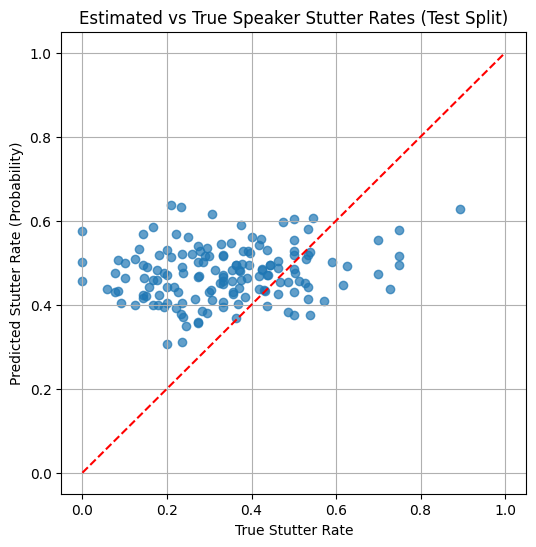

In [21]:
# Store predictions inside df_working for simplified grouping calculations
df_working.loc[df_working['split'] == 'test', 'lr_prob'] = lr_test_probs
df_working.loc[df_working['split'] == 'test', 'lr_pred'] = lr_test_preds

test_speakers = df_working[df_working['split'] == 'test'].groupby('speaker')
spk_rates = []

for spk, group in test_speakers:
    if len(group) >= 10:
        spk_rates.append({
            'speaker': spk,
            'true_rate': group['stutter'].mean(),
            'pred_rate_label': group['lr_pred'].mean(),
            'pred_rate_prob': group['lr_prob'].mean()
        })

spk_df = pd.DataFrame(spk_rates)
print(f"Number of test speakers with >= 10 clips: {len(spk_df)}")

spearman_label, _ = stats.spearmanr(spk_df['true_rate'], spk_df['pred_rate_label'])
spearman_prob, _ = stats.spearmanr(spk_df['true_rate'], spk_df['pred_rate_prob'])
mae_label = np.mean(np.abs(spk_df['true_rate'] - spk_df['pred_rate_label']))
mae_prob = np.mean(np.abs(spk_df['true_rate'] - spk_df['pred_rate_prob']))

print(f"Spearman (label): {spearman_label:.3f} | MAE (label): {mae_label:.3f}")
print(f"Spearman (prob): {spearman_prob:.3f} | MAE (prob): {mae_prob:.3f}")

plt.figure(figsize=(6, 6))
plt.scatter(spk_df['true_rate'], spk_df['pred_rate_prob'], alpha=0.7)
plt.plot([0, 1], [0, 1], 'r--')
plt.xlabel('True Stutter Rate')
plt.ylabel('Predicted Stutter Rate (Probability)')
plt.title('Estimated vs True Speaker Stutter Rates (Test Split)')
plt.grid(True)
plt.show()

Evaluate model performance (Recall and False Positive Rate) across defined gender subgroups in the test set.

In [22]:
for gender_val in ['f', 'm', 'd']:
    g_sub = df_working[(df_working['split'] == 'test') & (df_working['gender'] == gender_val)]
    if len(g_sub) > 0:
        y_g = g_sub['stutter'].values
        pred_g = g_sub['lr_pred'].values

        rec = recall_score(y_g, pred_g, zero_division=0)
        tn, fp, fn, tp = confusion_matrix(y_g, pred_g, labels=[0, 1]).ravel()
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

        print(f"Gender: {gender_val} | Clip Count: {len(g_sub)} | Recall: {rec:.3f} | FPR: {fpr:.3f}")

Gender: f | Clip Count: 2034 | Recall: 0.474 | FPR: 0.379
Gender: m | Clip Count: 3195 | Recall: 0.421 | FPR: 0.389
Gender: d | Clip Count: 782 | Recall: 0.380 | FPR: 0.318


Save predictions for both calib and test sets as the final handover file.

In [23]:
# Map probabilities/predictions to the calib split as well
calib_mask = df_working['split'] == 'calib'
X_calib_scaled = scaler.transform(df_working[calib_mask][feat_cols].values)
df_working.loc[calib_mask, 'lr_prob'] = clf.predict_proba(X_calib_scaled)[:, 1]
df_working.loc[calib_mask, 'lr_pred'] = clf.predict(X_calib_scaled)

handover_df = df_working[df_working['split'].isin(['calib', 'test'])][
    ['Show', 'EpId', 'ClipId', 'speaker', 'gender', 'split', 'stutter', 'lr_prob', 'lr_pred']
]
handover_df.to_csv('predictions_baseline.csv', index=False)
print("Saved prediction results to predictions_baseline.csv")

Saved prediction results to predictions_baseline.csv



# Model 1: frozen wav2vec2 embeddings + logistic regression

This section uses a frozen pre-trained `facebook/wav2vec2-base` model on the GPU (T4 or better) to extract 13 layers of 768-dimensional speech features, optimizes layer selection on the `calib` split, and evaluates the final system against the baseline.


In [24]:
import torch
from transformers import AutoFeatureExtractor, Wav2Vec2Model
import shutil

# GPU Check
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Active Device:", torch.cuda.get_device_name(0))

CUDA available: True
Active Device: Tesla T4


In [25]:
# 1. Setup Feature Extractor & Model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model_name = "facebook/wav2vec2-base"

feature_extractor = AutoFeatureExtractor.from_pretrained(model_name)
model = Wav2Vec2Model.from_pretrained(model_name, output_hidden_states=True)
model.eval()
model.to(device)
if device.type == 'cuda':
    model.half() # Use float16 on GPU

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  380MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


model.safetensors: reconstructing file:   0%|          |  0.00B /  380MB            

model.safetensors: downloading bytes:           |  0.00B            

In [26]:
# 2. Extract or Load Frozen Wav2Vec2 Features with strict caching rules
from google.colab import drive
import numpy as np
import os

mount_path = '/content/drive'
if not os.path.exists(mount_path):
    try:
        drive.mount(mount_path)
    except Exception as e:
        print("Google Drive mount skipped or failed. Continuing locally.")

gdrive_dir = '/content/drive/MyDrive/stutter_w2v_cache'
local_w2v_feats_path = 'w2v_feats.npy'
local_w2v_keys_path = 'w2v_keys.csv'
gdrive_w2v_feats_path = os.path.join(gdrive_dir, 'w2v_feats.npy')
gdrive_w2v_keys_path = os.path.join(gdrive_dir, 'w2v_keys.csv')

def check_alignment(k_df, f_df):
    if len(k_df) != len(f_df):
        return False
    for col in ['Show', 'EpId', 'ClipId']:
        if not (k_df[col].values == f_df[col].values).all():
            return False
    return True

# Try downloading from GDrive first
if os.path.exists(gdrive_w2v_feats_path) and os.path.exists(gdrive_w2v_keys_path):
    print("Copying cache files from Google Drive to local workspace...")
    os.makedirs(gdrive_dir, exist_ok=True)
    shutil.copy(gdrive_w2v_feats_path, local_w2v_feats_path)
    shutil.copy(gdrive_w2v_keys_path, local_w2v_keys_path)

w2v_features = None
w2v_keys_df = None

if os.path.exists(local_w2v_feats_path) and os.path.exists(local_w2v_keys_path):
    print("Loading w2v features and keys from local cache...")
    w2v_features = np.load(local_w2v_feats_path)
    w2v_keys_df = pd.read_csv(local_w2v_keys_path)

    w2v_keys_df['Show'] = w2v_keys_df['Show'].astype(str).str.strip()
    w2v_keys_df['EpId'] = w2v_keys_df['EpId'].astype(int)
    w2v_keys_df['ClipId'] = w2v_keys_df['ClipId'].astype(int)

    if not check_alignment(w2v_keys_df, df_filtered):
        print("W2V cache mismatch! Deleting and rebuilding...")
        if os.path.exists(local_w2v_feats_path): os.remove(local_w2v_feats_path)
        if os.path.exists(local_w2v_keys_path): os.remove(local_w2v_keys_path)
        w2v_features = None
        w2v_keys_df = None

if w2v_features is None:
    print("Extracting Wav2Vec2 base embeddings layer-by-layer (13 layers) for all clips...")
    all_mean_pooled = []
    keys_list = []
    batch_size = 32
    n_clips = len(df_filtered)

    for start_idx in tqdm(range(0, n_clips, batch_size)):
        batch_df = df_filtered.iloc[start_idx : start_idx + batch_size]

        # Retrieve raw audios
        raw_audios = []
        raw_lengths = []
        for _, row in batch_df.iterrows():
            key = (row['Show'], int(row['EpId']), int(row['ClipId']))
            ds_idx = audio_lookup[key]
            sample = ds_full['train'][ds_idx]
            audio_arr = sample['audio']['array']
            raw_audios.append(audio_arr)
            raw_lengths.append(len(audio_arr))
            keys_list.append({
                'Show': row['Show'],
                'EpId': int(row['EpId']),
                'ClipId': int(row['ClipId'])
            })

        # Preprocess and Pad
        inputs = feature_extractor(raw_audios, sampling_rate=16000, padding=True, return_tensors="pt")
        input_values = inputs["input_values"].to(device)
        if device.type == 'cuda':
            input_values = input_values.half()

        # Compute exact valid frame length per clip using model's helper method
        raw_lengths_tensor = torch.tensor(raw_lengths, device=device)
        valid_frame_lengths = model._get_feat_extract_output_lengths(raw_lengths_tensor).tolist()

        with torch.no_grad():
            outputs = model(input_values)
            # output_hidden_states is a tuple of 13 tensors of shape [batch, frames, 768]
            hidden_states = outputs.hidden_states

        # Process each item in the batch
        for i, val_len in enumerate(valid_frame_lengths):
            clip_layers = []
            for layer in hidden_states:
                # Exclude padding frames using the computed valid length
                valid_frames = layer[i, :val_len, :] # shape: [val_len, 768]
                layer_mean = valid_frames.mean(dim=0).cpu().numpy()
                clip_layers.append(layer_mean)
            all_mean_pooled.append(np.array(clip_layers)) # [13, 768]

    w2v_features = np.array(all_mean_pooled, dtype=np.float16) # shape [n_clips, 13, 768]
    w2v_keys_df = pd.DataFrame(keys_list)

    np.save(local_w2v_feats_path, w2v_features)
    w2v_keys_df.to_csv(local_w2v_keys_path, index=False)

    # Upload/Save to Google Drive if active
    if os.path.exists(mount_path):
        try:
            os.makedirs(gdrive_dir, exist_ok=True)
            shutil.copy(local_w2v_feats_path, gdrive_w2v_feats_path)
            shutil.copy(local_w2v_keys_path, gdrive_w2v_keys_path)
            print("Cache successfully saved to Google Drive.")
        except Exception as e:
            print("Failed saving to Google Drive:", e)

    assert check_alignment(w2v_keys_df, df_filtered), "Mismatch between newly extracted w2v features and df_filtered!"
else:
    print("Wav2Vec2 features verified, matched, and loaded successfully.")

Google Drive mount skipped or failed. Continuing locally.
Extracting Wav2Vec2 base embeddings layer-by-layer (13 layers) for all clips...


  0%|          | 0/809 [00:00<?, ?it/s]

In [27]:
# 3. Layer optimization on the same dynamic capped split

# Create master features alignment for w2v
# Extract layer indices for training/eval matching the indices from df_working
train_mask = df_working['split'] == 'train'
calib_mask = df_working['split'] == 'calib'

# Retrieve absolute index pointers of df_working elements inside original df_filtered
working_indices = df_working.merge(
    df_filtered.reset_index(drop=True).reset_index().rename(columns={'index': 'orig_index'}),
    on=['Show', 'EpId', 'ClipId'],
    how='left'
)['orig_index'].values

# Split features by indices
X_train_w2v_all = w2v_features[working_indices[train_mask]]
y_train_w2v = df_working[train_mask]['stutter'].values

X_calib_w2v_all = w2v_features[working_indices[calib_mask]]
y_calib_w2v = df_working[calib_mask]['stutter'].values

best_layer = -1
best_auc = -1.0
layer_metrics = []

print("Optimizing layers over Calibration set...")
for layer_idx in range(13):
    X_tr_l = X_train_w2v_all[:, layer_idx, :].astype(np.float32)
    X_cal_l = X_calib_w2v_all[:, layer_idx, :].astype(np.float32)

    # Fit Scaler + Balanced LR
    l_scaler = StandardScaler()
    X_tr_l_s = l_scaler.fit_transform(X_tr_l)
    X_cal_l_s = l_scaler.transform(X_cal_l)

    l_clf = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
    l_clf.fit(X_tr_l_s, y_train_w2v)

    cal_probs = l_clf.predict_proba(X_cal_l_s)[:, 1]
    auc = roc_auc_score(y_calib_w2v, cal_probs)
    layer_metrics.append((layer_idx, auc))
    print(f"Layer {layer_idx:2d} | Calib AUROC: {auc:.4f}")

    if auc > best_auc:
        best_auc = auc
        best_layer = layer_idx

print(f"\nBest layer chosen: Layer {best_layer} (Calib AUROC: {best_auc:.4f})")

Optimizing layers over Calibration set...
Layer  0 | Calib AUROC: 0.6381
Layer  1 | Calib AUROC: 0.6680
Layer  2 | Calib AUROC: 0.6801
Layer  3 | Calib AUROC: 0.6936
Layer  4 | Calib AUROC: 0.7091
Layer  5 | Calib AUROC: 0.7111
Layer  6 | Calib AUROC: 0.7236
Layer  7 | Calib AUROC: 0.7234
Layer  8 | Calib AUROC: 0.7225
Layer  9 | Calib AUROC: 0.7323
Layer 10 | Calib AUROC: 0.7269
Layer 11 | Calib AUROC: 0.6789
Layer 12 | Calib AUROC: 0.6760

Best layer chosen: Layer 9 (Calib AUROC: 0.7323)


In [28]:
# 4. Train final model with the chosen best layer and compute complete evaluation metrics
X_train_best = X_train_w2v_all[:, best_layer, :].astype(np.float32)
w2v_scaler = StandardScaler()
X_train_scaled = w2v_scaler.fit_transform(X_train_best)

w2v_clf = LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42)
w2v_clf.fit(X_train_scaled, y_train_w2v)

# Run evaluations on calib and test sets
results = {}
for split_name in ['calib', 'test']:
    split_mask = df_working['split'] == split_name
    sub_indices = working_indices[split_mask]
    X_eval = w2v_features[sub_indices, best_layer, :].astype(np.float32)
    X_eval_scaled = w2v_scaler.transform(X_eval)
    y_eval = df_working[split_mask]['stutter'].values

    probs = w2v_clf.predict_proba(X_eval_scaled)[:, 1]
    preds = (probs >= 0.5).astype(int)

    # Store inside df_working
    df_working.loc[split_mask, 'w2v_prob'] = probs
    df_working.loc[split_mask, 'w2v_pred'] = preds

    # Calculate metrics
    acc = accuracy_score(y_eval, preds)
    prec = precision_score(y_eval, preds, zero_division=0)
    rec = recall_score(y_eval, preds, zero_division=0)
    f1 = f1_score(y_eval, preds, zero_division=0)
    auc = roc_auc_score(y_eval, probs)
    tn, fp, fn, tp = confusion_matrix(y_eval, preds).ravel()

    results[split_name] = {
        'acc': acc, 'prec': prec, 'rec': rec, 'f1': f1, 'auc': auc, 'fp': fp, 'fn': fn
    }

    print(f"\n=== {split_name.upper()} split Metrics (Wav2Vec2 Chosen Layer {best_layer}) ===")
    print(f"Acc: {acc:.3f} | Prec: {prec:.3f} | Rec: {rec:.3f} | F1: {f1:.3f} | AUC: {auc:.3f} | FP: {fp} | FN: {fn}")


=== CALIB split Metrics (Wav2Vec2 Chosen Layer 9) ===
Acc: 0.689 | Prec: 0.545 | Rec: 0.617 | F1: 0.579 | AUC: 0.732 | FP: 542 | FN: 404

=== TEST split Metrics (Wav2Vec2 Chosen Layer 9) ===
Acc: 0.674 | Prec: 0.546 | Rec: 0.574 | F1: 0.560 | AUC: 0.714 | FP: 1033 | FN: 924


=== Test Speaker-Level Rates Spearman Correlation & MAE ===
Spearman (label): 0.646 | MAE (label): 0.102
Spearman (prob): 0.653 | MAE (prob): 0.104


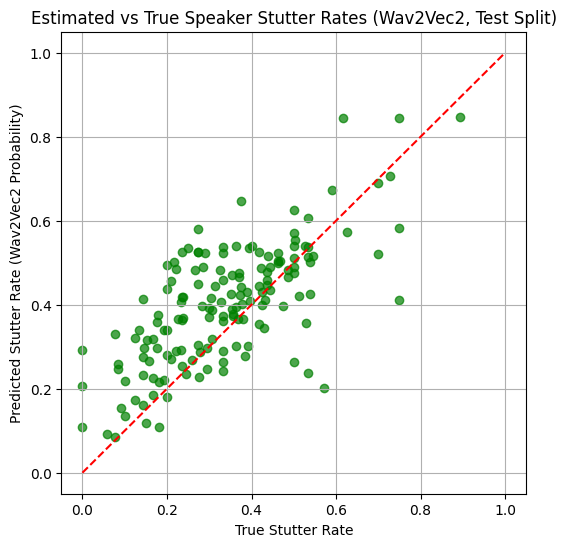

In [29]:
# Per-speaker analysis on test set (speakers with >= 10 clips)
test_mask = df_working['split'] == 'test'
test_speakers = df_working[test_mask].groupby('speaker')
spk_rates_w2v = []

for spk, group in test_speakers:
    if len(group) >= 10:
        spk_rates_w2v.append({
            'speaker': spk,
            'true_rate': group['stutter'].mean(),
            'pred_rate_label': group['w2v_pred'].mean(),
            'pred_rate_prob': group['w2v_prob'].mean()
        })

spk_w2v_df = pd.DataFrame(spk_rates_w2v)
spearman_label, _ = stats.spearmanr(spk_w2v_df['true_rate'], spk_w2v_df['pred_rate_label'])
spearman_prob, _ = stats.spearmanr(spk_w2v_df['true_rate'], spk_w2v_df['pred_rate_prob'])
mae_label = np.mean(np.abs(spk_w2v_df['true_rate'] - spk_w2v_df['pred_rate_label']))
mae_prob = np.mean(np.abs(spk_w2v_df['true_rate'] - spk_w2v_df['pred_rate_prob']))

print(f"=== Test Speaker-Level Rates Spearman Correlation & MAE ===")
print(f"Spearman (label): {spearman_label:.3f} | MAE (label): {mae_label:.3f}")
print(f"Spearman (prob): {spearman_prob:.3f} | MAE (prob): {mae_prob:.3f}")

# Scatter plot
plt.figure(figsize=(6, 6))
plt.scatter(spk_w2v_df['true_rate'], spk_w2v_df['pred_rate_prob'], alpha=0.7, color='green')
plt.plot([0, 1], [0, 1], 'r--')
plt.xlabel('True Stutter Rate')
plt.ylabel('Predicted Stutter Rate (Wav2Vec2 Probability)')
plt.title('Estimated vs True Speaker Stutter Rates (Wav2Vec2, Test Split)')
plt.grid(True)
plt.show()

In [30]:
# Per-gender analysis on test set
print("=== Wav2Vec2 Gender-subgroup performance ===")
for gender_val in ['f', 'm', 'd']:
    g_sub = df_working[test_mask & (df_working['gender'] == gender_val)]
    if len(g_sub) > 0:
        y_g = g_sub['stutter'].values
        pred_g = g_sub['w2v_pred'].values

        rec = recall_score(y_g, pred_g, zero_division=0)
        tn, fp, fn, tp = confusion_matrix(y_g, pred_g, labels=[0, 1]).ravel()
        fpr = fp / (fp + tn) if (fp + tn) > 0 else 0

        print(f"Gender: {gender_val} | Clip Count: {len(g_sub)} | Recall: {rec:.3f} | FPR: {fpr:.3f}")

=== Wav2Vec2 Gender-subgroup performance ===
Gender: f | Clip Count: 2034 | Recall: 0.609 | FPR: 0.261
Gender: m | Clip Count: 3195 | Recall: 0.578 | FPR: 0.287
Gender: d | Clip Count: 782 | Recall: 0.452 | FPR: 0.220


In [31]:
# 5. Consolidated Comparison Table on Test set
print(f"\n{'='*112}\n{'Model':<30} | {'Acc':<8} | {'Prec':<8} | {'Rec':<8} | {'F1':<8} | {'AUC':<8} | {'FP':<8} | {'FN':<8}\n{'='*112}")

# Retrieve baseline scores
y_test = df_working[test_mask]['stutter'].values

# Majority
maj_preds = np.full_like(y_test, majority_class)
maj_acc = accuracy_score(y_test, maj_preds)
maj_prec = precision_score(y_test, maj_preds, zero_division=0)
maj_rec = recall_score(y_test, maj_preds, zero_division=0)
maj_f1 = f1_score(y_test, maj_preds, zero_division=0)
maj_tn, maj_fp, maj_fn, maj_tp = confusion_matrix(y_test, maj_preds).ravel()
print(f"{'Majority Class':<30} | {maj_acc:.3f}    | {maj_prec:.3f}    | {maj_rec:.3f}    | {maj_f1:.3f}    | {0.5:.3f}    | {maj_fp:<8} | {maj_fn:<8}")

# MFCC
mfcc_acc = accuracy_score(y_test, df_working[test_mask]['lr_pred'])
mfcc_prec = precision_score(y_test, df_working[test_mask]['lr_pred'], zero_division=0)
mfcc_rec = recall_score(y_test, df_working[test_mask]['lr_pred'], zero_division=0)
mfcc_f1 = f1_score(y_test, df_working[test_mask]['lr_pred'], zero_division=0)
mfcc_auc = roc_auc_score(y_test, df_working[test_mask]['lr_prob'])
mfcc_tn, mfcc_fp, mfcc_fn, mfcc_tp = confusion_matrix(y_test, df_working[test_mask]['lr_pred']).ravel()
print(f"{'MFCC + Logistic Regression':<30} | {mfcc_acc:.3f}    | {mfcc_prec:.3f}    | {mfcc_rec:.3f}    | {mfcc_f1:.3f}    | {mfcc_auc:.3f}    | {mfcc_fp:<8} | {mfcc_fn:<8}")

# Wav2Vec2
w2v_acc = results['test']['acc']
w2v_prec = results['test']['prec']
w2v_rec = results['test']['rec']
w2v_f1 = results['test']['f1']
w2v_auc = results['test']['auc']
w2v_fp = results['test']['fp']
w2v_fn = results['test']['fn']
print(f"{'Wav2Vec2 (L' + str(best_layer) + ') + Logistic Reg':<30} | {w2v_acc:.3f}    | {w2v_prec:.3f}    | {w2v_rec:.3f}    | {w2v_f1:.3f}    | {w2v_auc:.3f}    | {w2v_fp:<8} | {w2v_fn:<8}")
print('='*112)


Model                          | Acc      | Prec     | Rec      | F1       | AUC      | FP       | FN      
Majority Class                 | 0.639    | 0.000    | 0.000    | 0.000    | 0.500    | 0        | 2168    
MFCC + Logistic Regression     | 0.556    | 0.395    | 0.434    | 0.413    | 0.533    | 1443     | 1227    
Wav2Vec2 (L9) + Logistic Reg   | 0.674    | 0.546    | 0.574    | 0.560    | 0.714    | 1033     | 924     


In [32]:
# 6. Build the enhanced predictions.csv handover file
if os.path.exists('predictions_baseline.csv'):
    handover_baseline = pd.read_csv('predictions_baseline.csv')

    # Align predictions based on specific key columns rather than sequence indices
    eval_subset = df_working[df_working['split'].isin(['calib', 'test'])]

    # Merge on identifier columns
    handover_new = handover_baseline.merge(
        eval_subset[['Show', 'EpId', 'ClipId', 'w2v_prob', 'w2v_pred']],
        on=['Show', 'EpId', 'ClipId'],
        how='left'
    )

    handover_new.to_csv('predictions.csv', index=False)
    print("Combined baseline and Wav2Vec2 predictions saved to 'predictions.csv'")

Combined baseline and Wav2Vec2 predictions saved to 'predictions.csv'



# Calibration correction (per-speaker rate)

This section uses the model's predictions on the `calib` split to compute correction terms ($TPR$, $FPR$, $p0$, $p1$), adjusts estimated speaker-level stuttering rates using both adjusted counts (`acc`) and probabilistic adjusted counts (`pacc`), and evaluates overall MAE, bias, Spearman correlation, and bootstrap confidence intervals on the `test` split.


In [33]:
# 1. Compute calibration terms on calib split
calib_subset = df_working[df_working['split'] == 'calib']
y_calib = calib_subset['stutter'].values
preds_calib = calib_subset['w2v_pred'].values
probs_calib = calib_subset['w2v_prob'].values

# Confusion matrix values
tn, fp, fn, tp = confusion_matrix(y_calib, preds_calib).ravel()
TPR = tp / (tp + fn) if (tp + fn) > 0 else 1.0
FPR = fp / (fp + tn) if (fp + tn) > 0 else 0.0

# Mean probabilities for true positives (p1) and true negatives (p0)
p1 = probs_calib[y_calib == 1].mean()
p0 = probs_calib[y_calib == 0].mean()

print(f"=== Calibration Split Calibration Metrics ===")
print(f"TPR: {TPR:.4f}")
print(f"FPR: {FPR:.4f}")
print(f"p0 (mean prob on TN): {p0:.4f}")
print(f"p1 (mean prob on TP): {p1:.4f}")

=== Calibration Split Calibration Metrics ===
TPR: 0.6167
FPR: 0.2733
p0 (mean prob on TN): 0.3268
p1 (mean prob on TP): 0.5977


In [34]:
# 2. Compute adjusted rates for each test speaker with >= 10 clips
test_subset = df_working[df_working['split'] == 'test']
test_speakers = test_subset.groupby('speaker')

spk_calibrated = []
clip_acc_lower = 0
clip_acc_upper = 0
clip_pacc_lower = 0
clip_pacc_upper = 0

for spk, group in test_speakers:
    n_clips = len(group)
    if n_clips >= 10:
        true_rate = group['stutter'].mean()
        gender = group['gender'].iloc[0] if 'gender' in group.columns else 'unknown'

        raw_label = group['w2v_pred'].mean()
        raw_prob = group['w2v_prob'].mean()

        # adjusted count (acc)
        denom_acc = TPR - FPR
        val_acc = (raw_label - FPR) / denom_acc if denom_acc != 0 else raw_label
        if val_acc < 0.0:
            clip_acc_lower += 1
            acc = 0.0
        elif val_acc > 1.0:
            clip_acc_upper += 1
            acc = 1.0
        else:
            acc = val_acc

        # probabilistic adjusted count (pacc)
        denom_pacc = p1 - p0
        val_pacc = (raw_prob - p0) / denom_pacc if denom_pacc != 0 else raw_prob
        if val_pacc < 0.0:
            clip_pacc_lower += 1
            pacc = 0.0
        elif val_pacc > 1.0:
            clip_pacc_upper += 1
            pacc = 1.0
        else:
            pacc = val_pacc

        spk_calibrated.append({
            'speaker': spk,
            'gender': gender,
            'n_clips': n_clips,
            'true_rate': true_rate,
            'raw_label': raw_label,
            'raw_prob': raw_prob,
            'acc': acc,
            'pacc': pacc
        })

spk_calib_df = pd.DataFrame(spk_calibrated)

print("=== Clipping Statistics ===")
print(f"acc clipped at 0.0: {clip_acc_lower} | acc clipped at 1.0: {clip_acc_upper}")
print(f"pacc clipped at 0.0: {clip_pacc_lower} | pacc clipped at 1.0: {clip_pacc_upper}")

=== Clipping Statistics ===
acc clipped at 0.0: 50 | acc clipped at 1.0: 13
pacc clipped at 0.0: 49 | pacc clipped at 1.0: 9


In [35]:
# 3. Report comparative table of estimators
estimators = ['raw_label', 'raw_prob', 'acc', 'pacc']
metrics_summary = []

for est in estimators:
    errors = spk_calib_df[est] - spk_calib_df['true_rate']
    mae = np.mean(np.abs(errors))
    bias = np.mean(errors)
    corr, _ = stats.spearmanr(spk_calib_df['true_rate'], spk_calib_df[est])

    metrics_summary.append({
        'Estimator': est,
        'MAE': mae,
        'Bias (Signed)': bias,
        'Spearman r': corr
    })

metrics_summary_df = pd.DataFrame(metrics_summary)
print("=== Comparative Speaker Rate Estimator Table ===")
display(metrics_summary_df)

=== Comparative Speaker Rate Estimator Table ===


,Estimator,MAE,Bias (Signed),Spearman r
0,raw_label,0.102131,0.024347,0.645684
1,raw_prob,0.104461,0.062820,0.653009
2,acc,0.218075,-0.001106,0.639144
3,pacc,0.211694,0.010552,0.640358


In [36]:
# 4. Paired speaker bootstrap (1000 resamples, rng seed 42)
rng = np.random.default_rng(42)
n_boot = 1000
n_spks = len(spk_calib_df)

diff_prob_pacc = []
diff_label_acc = []

for _ in range(n_boot):
    boot_idx = rng.choice(n_spks, size=n_spks, replace=True)
    boot_sample = spk_calib_df.iloc[boot_idx]

    mae_raw_prob = np.mean(np.abs(boot_sample['raw_prob'] - boot_sample['true_rate']))
    mae_pacc = np.mean(np.abs(boot_sample['pacc'] - boot_sample['true_rate']))

    mae_raw_label = np.mean(np.abs(boot_sample['raw_label'] - boot_sample['true_rate']))
    mae_acc = np.mean(np.abs(boot_sample['acc'] - boot_sample['true_rate']))

    diff_prob_pacc.append(mae_raw_prob - mae_pacc)
    diff_label_acc.append(mae_raw_label - mae_acc)

ci_prob_pacc = np.percentile(diff_prob_pacc, [2.5, 97.5])
ci_label_acc = np.percentile(diff_label_acc, [2.5, 97.5])

print("=== Paired Speaker Bootstrap 95% Confidence Intervals ===")
print(f"MAE(raw_prob) - MAE(pacc) CI: [{ci_prob_pacc[0]:.4f}, {ci_prob_pacc[1]:.4f}]")
print(f"MAE(raw_label) - MAE(acc) CI:   [{ci_label_acc[0]:.4f}, {ci_label_acc[1]:.4f}]")

=== Paired Speaker Bootstrap 95% Confidence Intervals ===
MAE(raw_prob) - MAE(pacc) CI: [-0.1267, -0.0869]
MAE(raw_label) - MAE(acc) CI:   [-0.1335, -0.1003]


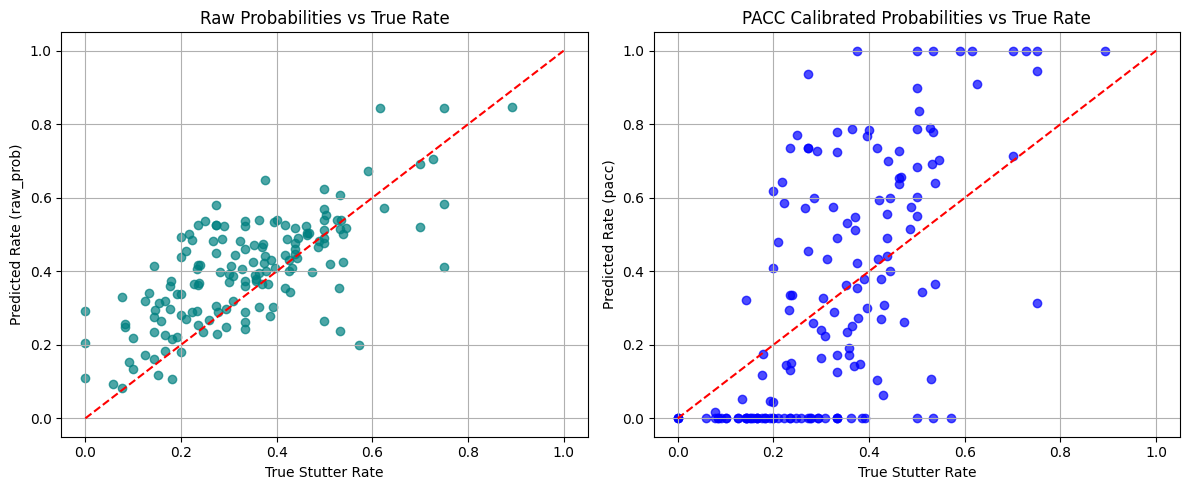

In [37]:
# 5. Plot True vs Predicted rate side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Left Plot: raw_prob
axes[0].scatter(spk_calib_df['true_rate'], spk_calib_df['raw_prob'], alpha=0.7, color='teal')
axes[0].plot([0, 1], [0, 1], 'r--')
axes[0].set_xlim([-0.05, 1.05])
axes[0].set_ylim([-0.05, 1.05])
axes[0].set_xlabel('True Stutter Rate')
axes[0].set_ylabel('Predicted Rate (raw_prob)')
axes[0].set_title('Raw Probabilities vs True Rate')
axes[0].grid(True)

# Right Plot: pacc
axes[1].scatter(spk_calib_df['true_rate'], spk_calib_df['pacc'], alpha=0.7, color='blue')
axes[1].plot([0, 1], [0, 1], 'r--')
axes[1].set_xlim([-0.05, 1.05])
axes[1].set_ylim([-0.05, 1.05])
axes[1].set_xlabel('True Stutter Rate')
axes[1].set_ylabel('Predicted Rate (pacc)')
axes[1].set_title('PACC Calibrated Probabilities vs True Rate')
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [38]:
# 6. Save per-speaker results
spk_calib_df.to_csv('speaker_rates.csv', index=False)
print("Speaker calibration results successfully saved to 'speaker_rates.csv'")

Speaker calibration results successfully saved to 'speaker_rates.csv'
